In [2]:
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras

In [3]:
tf.config.set_visible_devices([], 'GPU')

LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28

observation_entrainement = pnd.read_csv('data/fashion-mnist_test.csv')

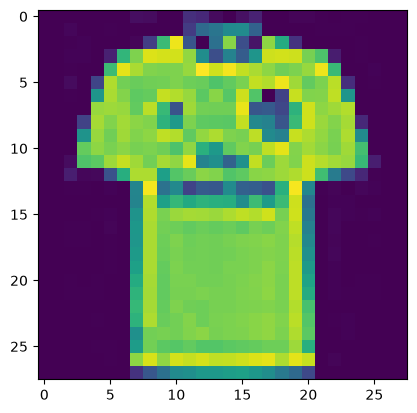

In [4]:
X = np.array(observation_entrainement.iloc[:, 1:])

premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE, LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

In [5]:
Y = keras.utils.to_categorical(np.array(observation_entrainement.iloc[:, 0]))

X_apprentissage, X_validation, Y_apprentissage, Y_validation = train_test_split(X, Y, test_size = 0.2, random_state = 13)

In [6]:
X_apprentissage = X_apprentissage.reshape(X_apprentissage.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255

X_validation = X_validation.reshape(X_validation.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

X_validation = X_validation.astype('float32')
X_validation /= 255

In [13]:
observation_test = pnd.read_csv('data/fashion-mnist_test.csv')
X_test = np.array(observation_test.iloc[:, 1:])
Y_test = tf.keras.utils.to_categorical(np.array(observation_test.iloc[:, 0]))
X_test = X_test.reshape(X_test.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)
X_test = X_test.astype('float32')
X_test /= 255

In [8]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

In [9]:
dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

reseauNeurone1Convolution = Sequential()

reseauNeurone1Convolution.add(Input(shape = dimentionImage))
reseauNeurone1Convolution.add(Conv2D(32, kernel_size = (3, 3), activation = 'relu'))
reseauNeurone1Convolution.add(MaxPooling2D(pool_size = (2, 2)))
reseauNeurone1Convolution.add(Dropout(0.2))
reseauNeurone1Convolution.add(Flatten())
reseauNeurone1Convolution.add(Dense(128, activation = 'relu'))
reseauNeurone1Convolution.add(Dense(10, activation = 'softmax'))

In [10]:
reseauNeurone1Convolution.compile(loss = keras.losses.categorical_crossentropy, optimizer = tf.keras.optimizers.Adam(), metrics = ['accuracy'])

In [11]:
historique_apprentissage = reseauNeurone1Convolution.fit(X_apprentissage, Y_apprentissage, batch_size = 256, epochs = 10, verbose = 1, validation_data = (X_validation, Y_validation))

Epoch 1/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step - accuracy: 0.6811 - loss: 0.9682 - val_accuracy: 0.7970 - val_loss: 0.5611
Epoch 2/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.8136 - loss: 0.5210 - val_accuracy: 0.8335 - val_loss: 0.4712
Epoch 3/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.8482 - loss: 0.4471 - val_accuracy: 0.8600 - val_loss: 0.4222
Epoch 4/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.8591 - loss: 0.4050 - val_accuracy: 0.8560 - val_loss: 0.4096
Epoch 5/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.8727 - loss: 0.3693 - val_accuracy: 0.8705 - val_loss: 0.3831
Epoch 6/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.8825 - loss: 0.3437 - val_accuracy: 0.8690 - val_loss: 0.3740
Epoch 7/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.8884 - loss: 0.3259 - val_accuracy: 0.8580 - val_loss: 0.4088
Epoch 8/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.8923 - loss: 0.3123 - val_accuracy: 0.8715 - v

In [14]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, Y_test, verbose = 0)
print('Erreur : ', evaluation[0])
print('Precision : ', evaluation[1])

Erreur :  0.27125832438468933
Precision :  0.9067999720573425


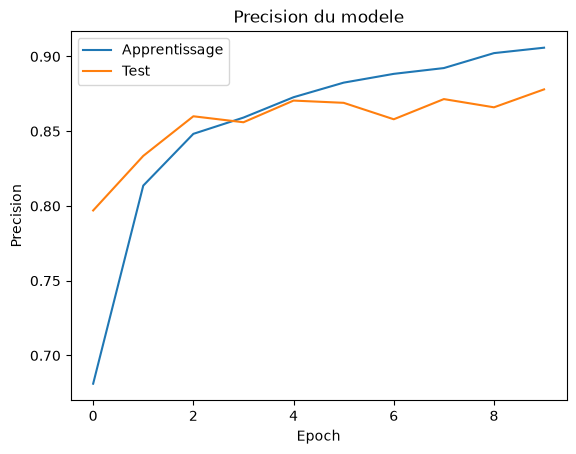

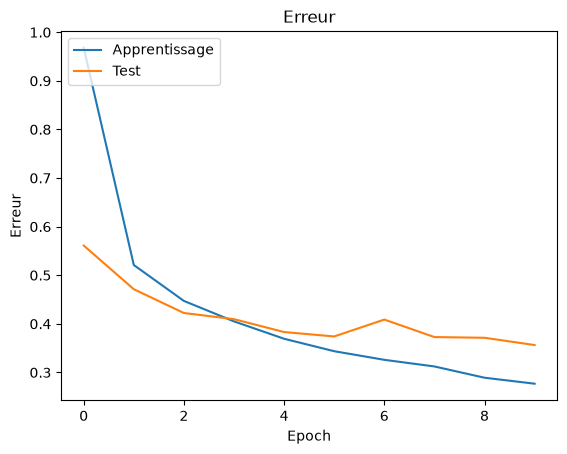

In [15]:
plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Precision du modele')
plt.ylabel('Precision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc = 'upper left')
plt.show()

plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Erreur')
plt.ylabel('Erreur')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc = 'upper left')
plt.show()